<a href="https://colab.research.google.com/github/smir-nat/AK/blob/main/lab8/DBSCAN.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Повний розмір датасету: (40000, 25)

Розподіл об'єктів за кластерами (-1 позначає викиди/шум):
Cluster
-1      65
 0    1212
 1     171
 2      24
 3      28
Name: count, dtype: int64


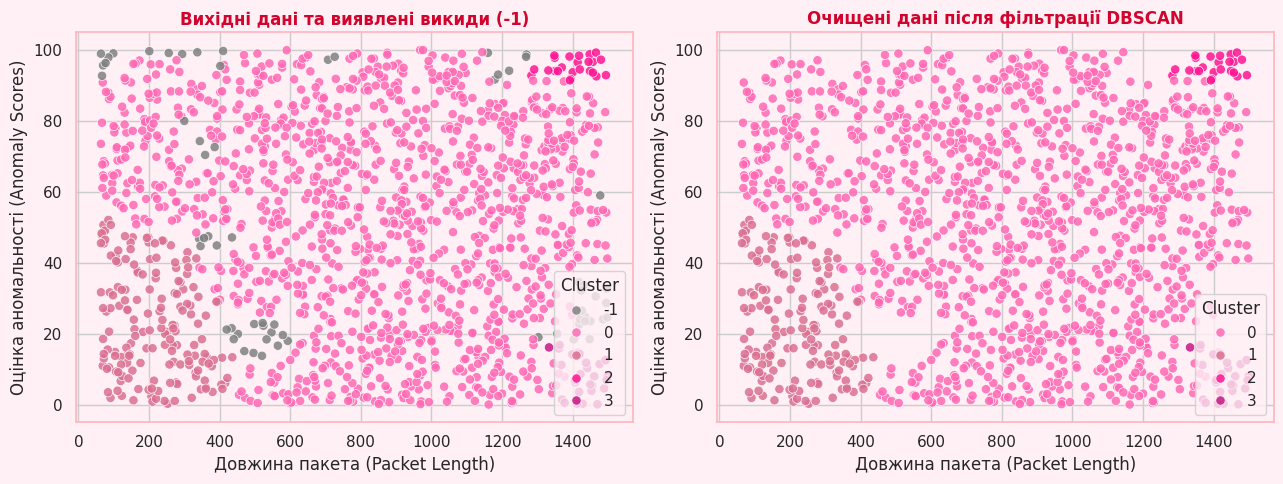


Точність Контрольної групи (Модель A - Logistic Regression): 0.3275
Точність Тестової групи (Модель B - Random Forest): 0.3554
Тестова група (Модель B) перевершила контрольну групу на тестовій вибірці
Крос-валідація (10 фолдів) -> Модель A: 0.3345 | Модель B: 0.3143
t-статистика: -1.1212, p-value: 0.2912


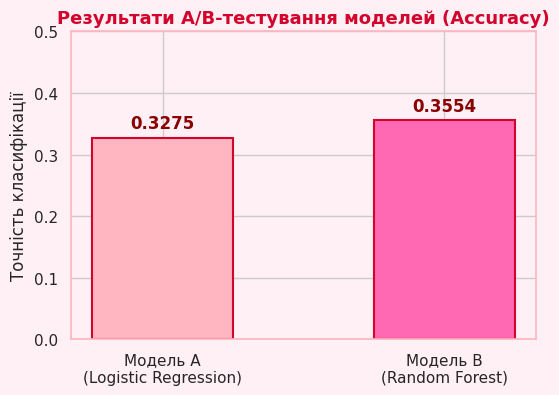

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.cluster import DBSCAN
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score, classification_report
from scipy import stats

# Налаштування пастельно-рожевої палітри
sns.set_theme(style="whitegrid", rc={
    "axes.facecolor": "#FFF0F5",
    "figure.facecolor": "#FFF0F5",
    "axes.edgecolor": "#FFB6C1"
})

# 1. Завантаження даних з твого GitHub (raw-посилання)
url = 'https://raw.githubusercontent.com/smir-nat/AK/main/lab8/cybersecurity_attacks.csv'
df = pd.read_csv(url)
print(f"Повний розмір датасету: {df.shape}")

# Беремо репрезентативну вибірку (1500 записів) для наочної кластеризації та швидкої роботи
df_sample = df.sample(n=1500, random_state=42).reset_index(drop=True)

# --- ЧАСТИНА 1: Метод кластеризації DBSCAN ---
# Обираємо ключові числові показники трафіку: довжина пакета та оцінка аномальності
features_db = ['Packet Length', 'Anomaly Scores']
scaler_db = StandardScaler()
X_db_scaled = scaler_db.fit_transform(df_sample[features_db])

# Застосовуємо DBSCAN (eps=0.2, min_samples=15)
dbscan = DBSCAN(eps=0.2, min_samples=15)
df_sample['Cluster'] = dbscan.fit_predict(X_db_scaled)

print("\nРозподіл об'єктів за кластерами (-1 позначає викиди/шум):")
print(df_sample['Cluster'].value_counts().sort_index())

# Візуалізація до та після очищення від викидів (як у методичці)
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
fig.patch.set_facecolor('#FFF0F5')

# Графік 1: Вихідні дані з виділенням шуму (-1)
palette_all = {-1: '#808080', 0: '#FF69B4', 1: '#DB7093', 2: '#FF1493', 3: '#C71585'}
sns.scatterplot(
    ax=axes[0], data=df_sample, x='Packet Length', y='Anomaly Scores',
    hue='Cluster', palette=palette_all, s=45, alpha=0.85, edgecolor='white'
)
axes[0].set_title('Вихідні дані та виявлені викиди (-1)', fontsize=12, fontweight='bold', color='#D2042D')
axes[0].set_xlabel('Довжина пакета (Packet Length)')
axes[0].set_ylabel('Оцінка аномальності (Anomaly Scores)')

# Графік 2: Очищені дані (без шумових точок Cluster == -1)
df_clean = df_sample[df_sample['Cluster'] != -1].copy()
sns.scatterplot(
    ax=axes[1], data=df_clean, x='Packet Length', y='Anomaly Scores',
    hue='Cluster', palette={k: v for k, v in palette_all.items() if k != -1},
    s=45, alpha=0.85, edgecolor='white'
)
axes[1].set_title('Очищені дані після фільтрації DBSCAN', fontsize=12, fontweight='bold', color='#D2042D')
axes[1].set_xlabel('Довжина пакета (Packet Length)')
axes[1].set_ylabel('Оцінка аномальності (Anomaly Scores)')

plt.tight_layout()
plt.show()

# --- ЧАСТИНА 2: A/B-тестування моделей машинного навчання ---
# Підготовка ознак на очищеному датасеті для класифікації типу атаки (Attack Type)
feature_cols = ['Source Port', 'Destination Port', 'Packet Length', 'Anomaly Scores', 'Protocol', 'Traffic Type', 'Severity Level']
X = pd.get_dummies(df_clean[feature_cols], drop_first=True)
y = LabelEncoder().fit_transform(df_clean['Attack Type'])

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Модель A (Контрольна група): Логістична регресія
model_a = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, random_state=42))
# Модель B (Тестова група): Випадковий ліс (Random Forest)
model_b = RandomForestClassifier(n_estimators=100, random_state=42)

model_a.fit(X_train, y_train)
model_b.fit(X_train, y_train)

pred_a = model_a.predict(X_test)
pred_b = model_b.predict(X_test)

# Бінарні результати влучань (1 - вгадано, 0 - помилка) для A/B-тесту
control_group = (pred_a == y_test).astype(int)
treatment_group = (pred_b == y_test).astype(int)

def ab_test(control, treatment):
    control_rate = np.mean(control)
    treatment_rate = np.mean(treatment)
    print(f"\nТочність Контрольної групи (Модель A - Logistic Regression): {control_rate:.4f}")
    print(f"Точність Тестової групи (Модель B - Random Forest): {treatment_rate:.4f}")
    if treatment_rate > control_rate:
        return "Тестова група (Модель B) перевершила контрольну групу на тестовій вибірці"
    elif treatment_rate < control_rate:
        return "Контрольна група (Модель A) перевершила тестову групу на тестовій вибірці"
    else:
        return "Суттєвої різниці між моделями не виявлено"

print(ab_test(control_group, treatment_group))

# Статистична перевірка на 10-кратній крос-валідації (парний t-тест Стьюдента)
cv_a = cross_val_score(model_a, X, y, cv=10, scoring='accuracy')
cv_b = cross_val_score(model_b, X, y, cv=10, scoring='accuracy')
t_stat, p_val = stats.ttest_rel(cv_b, cv_a)
print(f"Крос-валідація (10 фолдів) -> Модель A: {cv_a.mean():.4f} | Модель B: {cv_b.mean():.4f}")
print(f"t-статистика: {t_stat:.4f}, p-value: {p_val:.4f}")

# Візуалізація результатів A/B-тестування
plt.figure(figsize=(6, 4))
models = ['Модель A\n(Logistic Regression)', 'Модель B\n(Random Forest)']
scores = [np.mean(control_group), np.mean(treatment_group)]
bars = plt.bar(models, scores, color=['#FFB6C1', '#FF69B4'], edgecolor='#D2042D', linewidth=1.5, width=0.5)
plt.ylim(0, 0.5)
plt.title('Результати A/B-тестування моделей (Accuracy)', fontsize=13, fontweight='bold', color='#D2042D')
plt.ylabel('Точність класифікації')
for bar, score in zip(bars, scores):
    plt.text(bar.get_x() + bar.get_width()/2, score + 0.015, f"{score:.4f}", ha='center', fontweight='bold', color='#8B0000')
plt.show()